# Attribution visualization

**Business context:** stakeholders rarely accept raw attribution vectors. Coloured words, sorted bars and marked-up audio make Shapley and Banzhaf results legible in compliance reviews and product postmortems.

**Goal:** explain three inputs with a real model and show every built-in view: a single prompt (words as players), a multi-speaker conversation (messages as players) and a spoken sentence (words of the audio as players).

**Prerequisites:** `uv sync --extra viz --extra transformers --extra audio`. The first run downloads `Qwen/Qwen2.5-1.5B-Instruct` (3.1 GB) and `facebook/wav2vec2-base-960h` (0.36 GB); a GPU or Apple MPS keeps it to a few minutes.

**Expected output:** attributions of both signs and different sizes, rendered as coloured text, bar charts, HTML and an audio figure.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt

from nlp_shap import (
    AudioPart,
    ConversationSnapshot,
    ExplainConfig,
    ExplainRunner,
    Message,
    Role,
    TextPart,
    TokenBarRenderer,
    TokenTextRenderer,
    TransformersTextBackend,
    Turn,
    display_attribution_html,
    render_attribution,
    render_attribution_html,
)
from nlp_shap.plugins.context import PluginContext
from nlp_shap.viz import plot_audio_segments, plot_conversation, render_conversation_html

## One model for three explanations

Each coalition's 4-token answer is scored with `tfidf_cosine` against the answer to the full input, so a player earns credit when it moves the answer toward the original and loses credit when it moves it away. The pinned revision keeps the numbers reproducible, the prefix cache reuses shared prompt prefixes, and one backend is loaded once and passed to every runner.

In [2]:
MODEL = {
    "kind": "transformers",
    "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
    "options": {"revision": "989aa7980e4cf806f80c7fef2b1adb7bc71aa306", "dtype": "float16"},
}


def config(**explanation: object) -> ExplainConfig:
    return ExplainConfig.model_validate({
        "backend": MODEL,
        "generation": {"max_new_tokens": 4},
        "explanation": {
            "value_fn": "tfidf_cosine",
            "absence_policy": "delete",
            "kv_cache": {"enabled": True},
            "archive": {"path": ""},
            **explanation,
        },
    })


backend = TransformersTextBackend(PluginContext(config=config()))


def show(output) -> None:
    for span, value in zip(output.player_set.spans, output.result.values, strict=True):
        print(f"{span.display_label[:44]:44} {value:+.3f}")
    print("sum", round(sum(output.result.values), 4), "= grand - base",
          round(output.result.grand_value - output.result.base_value, 4))

## Words of a single prompt

**Business:** a support assistant is asked about a refund for a broken laptop that the customer already opened; reviewers want to see which words drive the answer.

**Technical:** 13 word players, complementary contributions with a budget of 160 evaluations (exact enumeration would need 8192).

In [3]:
prompt = ConversationSnapshot.from_turns((
    Turn(messages=(Message(
        role=Role.USER,
        text="The laptop arrived broken but I opened it. Refund? Answer yes or no.",
    ),)),
))
words = await ExplainRunner(
    config(estimator="complementary", budget={"evaluations": 160}), backend=backend
).explain(prompt)
show(words)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

The                                          -0.014
laptop                                       +0.149
arrived                                      +0.030
broken                                       -0.015
but                                          +0.039
I                                            +0.057
opened                                       -0.063
it.                                          -0.067
Refund?                                      +0.189
Answer                                       +0.179
yes                                          +0.310
or                                           +0.092
no.                                          +0.222
sum 1.1075 = grand - base 1.0


The question and its answer options carry most of the credit, `laptop` and `Refund?` push toward the original answer, and `opened it.` pulls against it: the opened box is what makes the model hesitate. The values add up to `grand_value - base_value`.

### Coloured words and bars

`render_attribution` returns a matplotlib figure; pass the run's `player_set` so labels match the players. Red marks positive values, blue negative ones, and the colour intensity follows the size. `token_bar` sorts the players by absolute value.

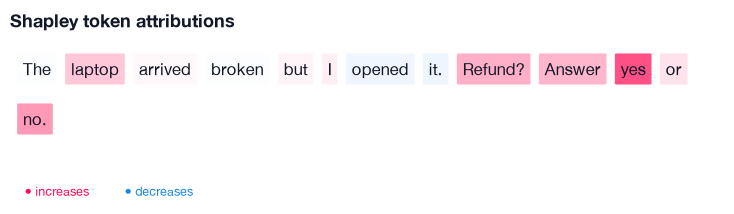

In [4]:
render_attribution(words, prompt, words.player_set, renderer="token_text")
plt.show()

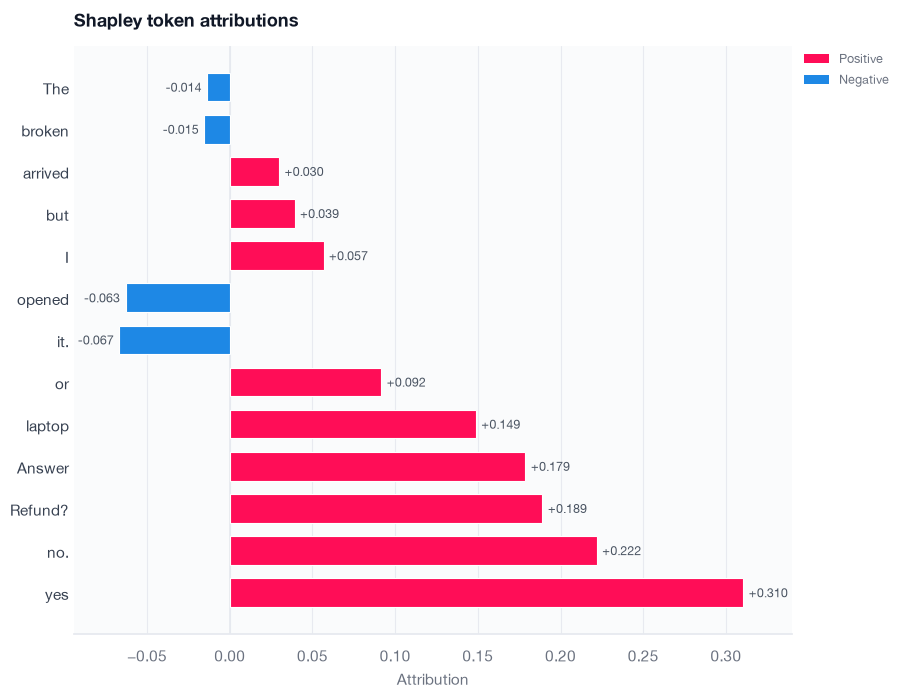

In [5]:
render_attribution(words, prompt, words.player_set, renderer="token_bar")
plt.show()

### HTML

In Jupyter, `display_attribution_html` shows the coloured words without matplotlib; `render_attribution_html` returns the same fragment as a string for reports and emails.

In [6]:
display_attribution_html(words, prompt, words.player_set, title="Refund request")
html = render_attribution_html(words, prompt, words.player_set, title="Refund request")
print(len(html), "characters;", html.count("background-color"), "coloured words")

2315 characters; 13 coloured words


## A multi-speaker conversation

**Business:** in a shared support thread, which message decided the answer, and whose?

**Technical:** `players: messages` makes each message one player, labelled with its role, speaker and position; five players allow exact enumeration (32 coalitions).

In [7]:
thread = ConversationSnapshot.from_turns((
    Turn(messages=(Message(role=Role.USER, speaker="Alice", text="I ordered a laptop on May 2."),)),
    Turn(messages=(Message(role=Role.ASSISTANT, text="Thanks. How can I help?"),)),
    Turn(messages=(Message(role=Role.USER, speaker="Bob", text="It arrived with a cracked screen."),)),
    Turn(messages=(Message(role=Role.USER, speaker="Alice", text="We used it once before we noticed."),)),
    Turn(messages=(Message(role=Role.USER, speaker="Bob", text="Can we get a refund? Answer yes or no."),)),
))
shapley_runner = ExplainRunner(config(estimator="exact", players="messages"), backend=backend)
messages = await shapley_runner.explain(thread)
show(messages)

user/Alice 1: I ordered a laptop on May 2.   +0.320
assistant 2: Thanks. How can I help?         +0.103
user/Bob 3: It arrived with a cracked scre…  +0.267
user/Alice 4: We used it once before we noti +0.043
user/Bob 5: Can we get a refund? Answer ye…  +0.267
sum 1.0 = grand - base 1.0


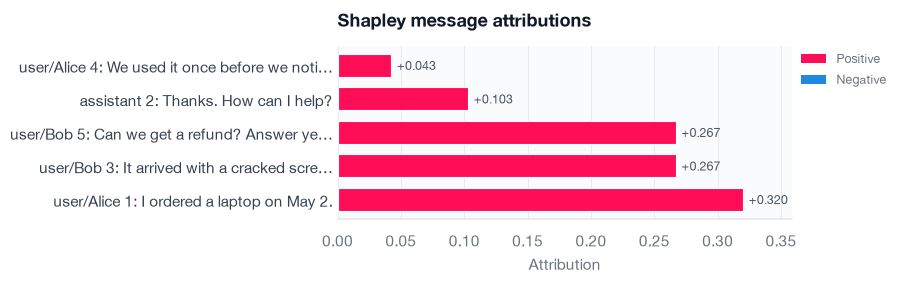

In [8]:
render_attribution(messages, thread, messages.player_set, renderer="token_bar",
                   title="Shapley message attributions")
plt.show()

`plot_conversation` keeps the thread's shape: one block per message under its role, speaker and position, with each player shaded where it stands. `render_conversation_html` returns the same view as HTML; hovering a player shows its value.

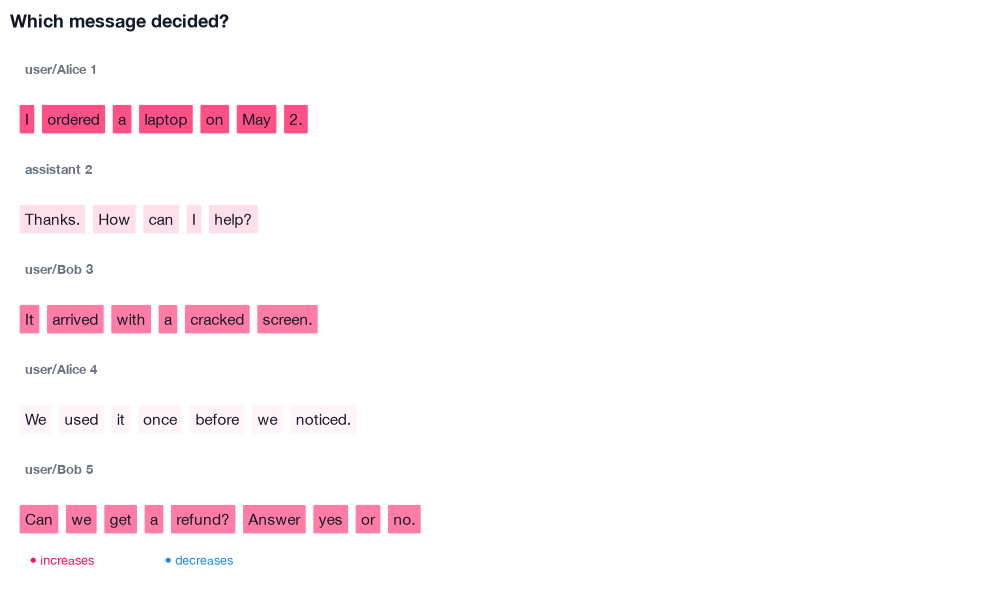

In [9]:
plot_conversation(messages, thread, messages.player_set, title="Which message decided?")
plt.show()

### Words of the users only

**Business:** reviewers care about what the customers wrote; the assistant's and system's text is context, not evidence.

**Technical:** `players: tokens` with `plugin_options: {tokens: {roles: [user]}}` makes only the users' words players; the assistant message stays present in every coalition and appears grey. The same `roles` option filters `players: messages`. 26 word players need a sampled estimator: complementary contributions with 200 evaluations.

In [10]:
user_words = await ExplainRunner(
    config(
        estimator="complementary",
        budget={"evaluations": 200},
        players="tokens",
        plugin_options={"tokens": {"roles": ["user"]}},
    ),
    backend=backend,
).explain(thread)
show(user_words)

Alice: I                                     +0.016
Alice: ordered                               +0.065
Alice: a                                     +0.016
Alice: laptop                                +0.025
Alice: on                                    +0.016
Alice: May                                   +0.041
Alice: 2.                                    +0.043
Bob: It                                      +0.042
Bob: arrived                                 +0.023
Bob: with                                    +0.017
Bob: a                                       -0.026
Bob: cracked                                 +0.032
Bob: screen.                                 +0.039
Alice: We                                    +0.002
Alice: used                                  +0.001
Alice: it                                    +0.019
Alice: once                                  +0.049
Alice: before                                -0.006
Alice: we                                    +0.031
Alice: notic

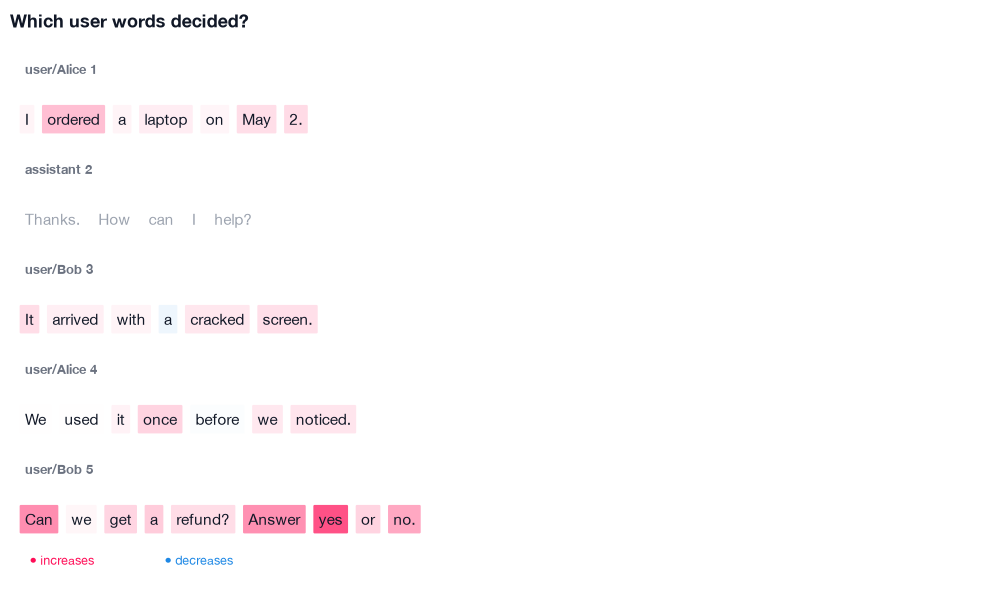

In [11]:
plot_conversation(user_words, thread, user_words.player_set, title="Which user words decided?")
plt.show()

In [12]:
html = render_conversation_html(user_words, thread, user_words.player_set)
print(html.count("nlp-shap-player"), "coloured user words; assistant text kept:", "How can I help?" in html)

29 coloured user words; assistant text kept: True


### Renderer classes and Banzhaf values

`TokenTextRenderer` and `TokenBarRenderer` are the plugin classes behind the renderer names: `render(labels, values, estimand=..., title=...)` draws any labelled vector, and `to_html` returns the HTML fragment. With `registry=runner.registry`, `render_attribution` resolves renderers you registered yourself. Without `title=`, the bar chart names the estimand, so a Banzhaf chart is not mistaken for Shapley values; Banzhaf values need not add up.

to_html matches: True


user/Alice 1: I ordered a laptop on May 2.   +0.180
assistant 2: Thanks. How can I help?         +0.044
user/Bob 3: It arrived with a cracked scre…  +0.153
user/Alice 4: We used it once before we noti +0.013
user/Bob 5: Can we get a refund? Answer ye…  +0.153
sum 0.5432 = grand - base 1.0


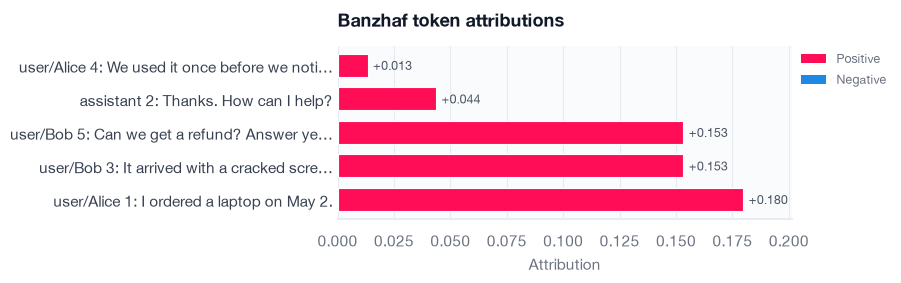

In [13]:
labels = [span.display_label for span in messages.player_set.spans]
print("to_html matches:", TokenTextRenderer().to_html(labels, messages.result.values,
      estimand=messages.result.estimand) == render_attribution_html(messages, thread, messages.player_set))
banzhaf_runner = ExplainRunner(
    config(estimator="exact", estimand="banzhaf", players="messages"), backend=backend
)
banzhaf = await banzhaf_runner.explain(thread)
show(banzhaf)
TokenBarRenderer().render(labels, banzhaf.result.values, estimand=banzhaf.result.estimand)
plt.show()

## Spoken words

**Business:** a voice assistant hears a sentence; which spoken words shaped its reading of the speaker's mood?

**Technical:** `players: sgpa_segments` aligns the recording (`data/voices_sp0307.wav`, VOiCES corpus, CC BY 4.0) to its transcript and makes each spoken word a player whose audio and text are masked together. No backend generates from audio yet, so a small wrapper hands the model the masked transcript.

In [14]:
class TranscriptReader:
    """Give the text model the masked transcript of each audio message."""

    model_id = backend.model_id

    async def generate(self, snapshot, generation):
        text_only = ConversationSnapshot.from_turns(tuple(
            Turn(messages=tuple(
                Message(role=m.role, text=m.text, speaker=m.speaker) for m in turn.messages
            ))
            for turn in snapshot.turns
        ))
        return await backend.generate(text_only, generation)


clip = AudioPart(Path("data/voices_sp0307.wav"), sample_rate=16000)
spoken = ConversationSnapshot.from_turns((Turn(messages=(
    Message(role=Role.USER, text="How did the speaker feel? Answer in one word."),
    Message(role=Role.USER, content=(TextPart("I had that curiosity beside me at this moment"), clip)),
)),))
audio_config = config(
    estimator="complementary", budget={"evaluations": 128}, players="sgpa_segments",
    plugin_options={"sgpa_segments": {
        "model_id": "facebook/wav2vec2-base-960h",
        "revision": "22aad52d435eb6dbaf354bdad9b0da84ce7d6156",
    }},
)
heard = await ExplainRunner(audio_config, backend=TranscriptReader()).explain(spoken)
show(heard)

Loading weights:   0%|          | 0/212 [00:00<?, ?it/s]

[transformers] Wav2Vec2ForCTC LOAD REPORT from: facebook/wav2vec2-base-960h
Key                        | Status  | 
---------------------------+---------+-
wav2vec2.masked_spec_embed | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


I                                            +0.179
had                                          +0.112
that                                         +0.125
curiosity                                    +0.197
beside                                       +0.090
me                                           +0.157
at                                           -0.058
this                                         +0.073
moment                                       +0.125
sum 0.9996 = grand - base 1.0


`plot_audio_segments` draws each word's stretch of audio coloured by its value, over the waveform and its energy; `token_bar` ranks the same players.

Loading weights:   0%|          | 0/212 [00:00<?, ?it/s]

[transformers] Wav2Vec2ForCTC LOAD REPORT from: facebook/wav2vec2-base-960h
Key                        | Status  | 
---------------------------+---------+-
wav2vec2.masked_spec_embed | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


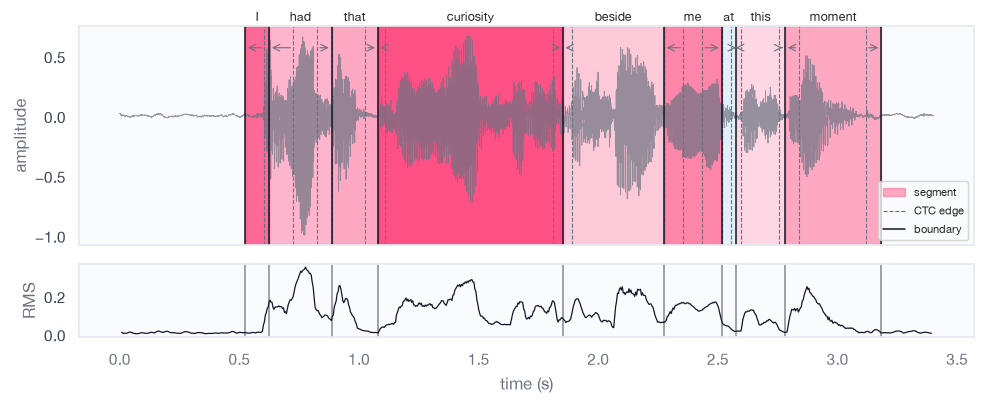

In [15]:
from nlp_shap.alignment import SpectrogramGuidedAligner, Wav2Vec2Ctc

aligner = SpectrogramGuidedAligner(Wav2Vec2Ctc(
    "facebook/wav2vec2-base-960h", revision="22aad52d435eb6dbaf354bdad9b0da84ce7d6156"))
segments = aligner.align("I had that curiosity beside me at this moment", clip)
plot_audio_segments(clip, segments, values=list(heard.result.values))
plt.show()

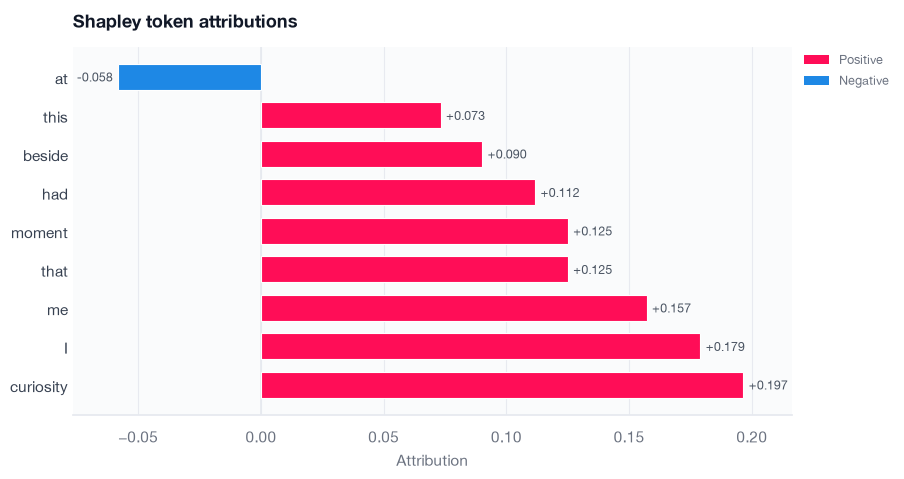

In [16]:
render_attribution(heard, spoken, heard.player_set, renderer="token_bar")
plt.show()